# LifeGuard-RL XJTU SOH error audit

Compare the current Linear SOH estimate with a correction for the first recorded cycle and with a Ridge correction for later charging cycles. The previous run found frequent large errors at the first recorded cycle and a persistent overestimate on XJTU_3C_battery-3.

1. Attach the same SOH dataset as the reliability notebook. It can contain **lifeguard_soh_results.zip**, **lifeguard_soh_validation_results.zip**, or the extracted **cycle_quality.csv** and **cycle_features.csv**.
2. Open this notebook in **Kaggle CPU** and run all cells. It reads the saved cycle tables.
3. Download **lifeguard_soh_error_audit_results.zip**. It includes the model comparison, separate first-cycle and hotspot checks, and all held-out predictions.

In [8]:
INPUT_ROOT = None
SOH_RESULTS_PATH = None  # Set to a SOH ZIP or extracted folder if needed.
OUTPUT_ROOT = None
SEED = 42

from collections import deque
from importlib.metadata import version
import json
from pathlib import Path, PurePosixPath
from tempfile import TemporaryDirectory
from zipfile import ZIP_DEFLATED, ZipFile

from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

if INPUT_ROOT is None:
    if Path("/kaggle/input").is_dir():
        INPUT_ROOT = "/kaggle/input"
    elif Path.cwd().name == "notebooks":
        INPUT_ROOT = Path.cwd().parent
    else:
        INPUT_ROOT = Path.cwd()
if OUTPUT_ROOT is None:
    OUTPUT_ROOT = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd() / "outputs"
INPUT_ROOT = Path(INPUT_ROOT).expanduser().resolve()
OUTPUT_ROOT = Path(OUTPUT_ROOT).expanduser().resolve()
if not INPUT_ROOT.is_dir():
    raise FileNotFoundError(f"Input folder does not exist: {INPUT_ROOT}")

## What each candidate uses

All three methods apply the same charge check used in the reliability benchmark. The first-cycle candidate uses normalized charge plus the median first-cycle offset learned from training cells. It uses the current Linear model on later cycles.

The history candidate also learns a Ridge correction to the Linear estimate on later cycles. Its features are charge passed through 3.8–4.0 V, charge passed through 4.0–4.1 V, and the change in total charge relative to the last five unflagged readings within ten cycles. The first recorded cycle has distinct behavior and is excluded from the history reference. The Ridge correction falls back to the Linear estimate when these features are unavailable.

The SOH label comes from discharged capacity. Current and previous charge features are the inputs for prediction. Discharge measurements are used for fitting and scoring on their respective cell splits.

In [9]:
KEY = ["cell_id", "cycle"]
FIXED_CELLS = {
    f"XJTU_{rate}C_battery-{number}": rate
    for rate, count in ((2, 8), (3, 15))
    for number in range(1, count + 1)
}
NOMINAL_AH = 2.0
HISTORY_SIZE = 10
MIN_FLAG_HISTORY = 5
MAD_MULTIPLIER = 6.0
FLAG_FLOORS = {"prefix_charge_ah": 0.08, "charge_duration_s": 120.0, "taper_duration_s": 120.0}
BASE_FIELDS = [*FLAG_FLOORS, "taper_charge_ah"]
VOLTAGE_FIELDS = ["rise_charge_3_8_to_4_0_ah", "rise_charge_4_0_to_4_1_ah"]
CHARGE_FIELDS = [*BASE_FIELDS, *VOLTAGE_FIELDS]
RESULT_ARCHIVES = ("lifeguard_soh_validation_results.zip", "lifeguard_soh_results.zip")
OUTLIER_CELL, OUTLIER_CYCLE = "XJTU_2C_battery-2", 390


def one_match(matches, description):
    matches = sorted(set(matches))
    if len(matches) != 1:
        raise ValueError(f"Expected one {description}, found {len(matches)}. Set SOH_RESULTS_PATH.")
    return matches[0]


def locate_soh_export(root):
    if SOH_RESULTS_PATH is not None:
        return Path(SOH_RESULTS_PATH).expanduser().resolve()
    for filename in RESULT_ARCHIVES:
        matches = list(root.rglob(filename))
        if matches:
            return one_match(matches, filename)
    folders = [p.parent for p in root.rglob("cycle_quality.csv") if (p.parent / "cycle_features.csv").is_file()]
    return one_match(folders, "folder with both cycle tables")


def load_cycles(source):
    names = ("cycle_quality.csv", "cycle_features.csv")
    if source.is_dir():
        quality, features = (pd.read_csv(source / name) for name in names)
    else:
        with ZipFile(source) as archive:
            tables = []
            for name in names:
                member = one_match([member for member in archive.namelist() if PurePosixPath(member).name == name], name)
                with archive.open(member) as stream:
                    tables.append(pd.read_csv(stream))
        quality, features = tables

    late = {f"late_taper_{name}": name for name in CHARGE_FIELDS}
    if all(name in features.columns for name in late):
        features = features.rename(columns=late)
    quality = quality[KEY + ["charge_rate_c", "discharge_capacity_ah"]].copy()
    features = features[KEY + CHARGE_FIELDS].copy()
    for frame in (quality, features):
        if frame[KEY].isna().any().any() or frame.duplicated(KEY).any():
            raise ValueError("The export must contain complete, unique cell and cycle keys.")
    if set(quality.cell_id) != set(FIXED_CELLS) or not quality.charge_rate_c.eq(quality.cell_id.map(FIXED_CELLS)).all():
        raise ValueError("Expected all 23 fixed-protocol XJTU cells with their documented rates.")
    feature_keys = features.merge(quality[KEY], on=KEY, how="left", indicator=True, validate="one_to_one")
    if not feature_keys["_merge"].eq("both").all():
        raise ValueError("Every charging feature row must have a matching cycle key in cycle_quality.csv.")
    if not np.isfinite(quality.discharge_capacity_ah).all() or not quality.discharge_capacity_ah.gt(0).all():
        raise ValueError("The XJTU evaluation requires finite, positive discharge capacity labels.")
    for cell, frame in quality.groupby("cell_id"):
        if not np.array_equal(np.sort(frame.cycle), np.arange(1, len(frame) + 1)):
            raise ValueError(f"Unexpected cycle numbers in {cell}.")
    quality["observed_soh_pct"] = 100.0 * quality.discharge_capacity_ah / NOMINAL_AH

    flags = flag_charge_traces(features)
    cycles = quality.merge(flags, on=KEY, how="left", validate="one_to_one").sort_values(KEY).reset_index(drop=True)
    cycles["trace_flagged"] = cycles.trace_flagged.eq(True)
    cycles["reference_ready"] = cycles.reference_ready.eq(True)
    values = cycles[BASE_FIELDS]
    cycles["input_valid"] = (
        np.isfinite(values).all(axis=1) & cycles.prefix_charge_ah.gt(0) & cycles.charge_duration_s.gt(0)
        & cycles.taper_duration_s.ge(0) & cycles.taper_duration_s.le(cycles.charge_duration_s)
        & cycles.taper_charge_ah.ge(0) & cycles.taper_charge_ah.le(cycles.prefix_charge_ah)
    )
    return cycles

In [10]:
def flag_charge_traces(features):
    by_cell = []
    for _, frame in features.groupby("cell_id", sort=False):
        frame = frame.sort_values("cycle").copy()
        marks = []
        for feature, floor in FLAG_FLOORS.items():
            values = frame[feature]
            valid = np.isfinite(values) & (values.ge(0) if feature == "taper_duration_s" else values.gt(0))
            # The shift keeps the current reading out of its own reference window.
            prior = values.where(valid).shift().rolling(HISTORY_SIZE, min_periods=MIN_FLAG_HISTORY)
            center = prior.median()
            mad = prior.apply(lambda window: np.nanmedian(np.abs(window - np.nanmedian(window))), raw=True)
            limit = (MAD_MULTIPLIER * 1.4826 * mad).clip(lower=floor)
            frame[f"{feature}_prior_median"] = center
            frame[f"{feature}_deviation_limit"] = limit
            flag = f"{feature}_flag"
            frame[flag] = ~valid | (values.sub(center).abs() > limit)
            marks.append(flag)
        frame["trace_flagged"] = frame[marks].any(axis=1)
        frame["reference_ready"] = frame[[f"{k}_prior_median" for k in FLAG_FLOORS]].notna().all(axis=1)
        by_cell.append(frame)
    return pd.concat(by_cell, ignore_index=True)

In [11]:
CURRENT = "current"
FALLBACK = "fallback"
UNCERTAIN = "uncertain_abnormal"
MISSING = "missing_charge_features"
FALLBACK_COUNT = 3


def guarded_estimates(rows, predictions):
    if rows.duplicated(KEY).any() or not rows.index.is_unique:
        raise ValueError("Guarding requires one row per cell and cycle.")
    estimates = pd.Series(predictions, index=rows.index, dtype=float)
    values = pd.Series(np.nan, index=rows.index)
    status = pd.Series(MISSING, index=rows.index, dtype=object)
    for _, cell in rows.sort_values(KEY).groupby("cell_id", sort=False):
        recent_clean = deque(maxlen=FALLBACK_COUNT)
        previous_status, previous_cycle = None, None
        for index, cycle, flagged in cell[["cycle", "trace_flagged"]].itertuples():
            raw = estimates.at[index]
            if np.isfinite(raw):
                if not flagged:
                    values.at[index] = raw
                    status.at[index] = CURRENT
                    recent_clean.append((cycle, raw))
                elif (previous_status == CURRENT and previous_cycle == cycle - 1
                      and len(recent_clean) == FALLBACK_COUNT and recent_clean[0][0] >= cycle - HISTORY_SIZE):
                    values.at[index] = float(np.median([value for _, value in recent_clean]))
                    status.at[index] = FALLBACK
                else:
                    status.at[index] = UNCERTAIN
            previous_status, previous_cycle = status.at[index], cycle
    return values, status


def check_guard_causality():
    rows = pd.DataFrame({
        "cell_id": ["a"] * 9 + ["b"] * 2,
        "cycle": [*range(1, 10), 1, 2],
        "trace_flagged": [False, False, False, True, True, False, False, True, False, True, False],
    })
    estimates = np.array([85.0, 84.0, 83.0, 96.0, 98.0, 80.0, np.nan, 95.0, 77.0, 91.0, 79.0])
    values, status = guarded_estimates(rows, estimates)
    assert status.tolist() == [CURRENT, CURRENT, CURRENT, FALLBACK, UNCERTAIN, CURRENT, MISSING,
                               UNCERTAIN, CURRENT, UNCERTAIN, CURRENT]
    assert values.iloc[3] == 84.0 and np.isnan(values.iloc[4])
    assert values.iloc[5] == 80.0 and values.iloc[8] == 77.0
    partial, partial_status = guarded_estimates(rows.iloc[:4], estimates[:4])
    pd.testing.assert_series_equal(partial, values.iloc[:4])
    pd.testing.assert_series_equal(partial_status, status.iloc[:4])

In [12]:
HISTORICAL_CHARGES = 5
HISTORY_DELTA = "charge_change_from_recent_median_ah"
RIDGE_FIELDS = [*VOLTAGE_FIELDS, HISTORY_DELTA]


def add_charge_history(cycles):
    history_delta = pd.Series(np.nan, index=cycles.index)
    for _, cell in cycles.sort_values(KEY).groupby("cell_id", sort=False):
        recent = deque(maxlen=HISTORICAL_CHARGES)
        columns = ["cycle", "prefix_charge_ah", "input_valid", "trace_flagged"]
        for index, cycle, charge, valid, flagged in cell[columns].itertuples():
            # The first cycle has its own calibration and is skipped as a history reference.
            if cycle == 1 or not valid or flagged:
                continue
            if len(recent) == HISTORICAL_CHARGES and recent[0][0] >= cycle - HISTORY_SIZE:
                history_delta.at[index] = charge - np.median([value for _, value in recent])
            recent.append((cycle, charge))

    result = cycles.assign(**{HISTORY_DELTA: history_delta})
    available = np.isfinite(result[RIDGE_FIELDS]).all(axis=1)
    windows = result[VOLTAGE_FIELDS]
    valid_windows = windows.ge(0).all(axis=1) & windows.sum(axis=1).le(result.prefix_charge_ah + 1e-6)
    result["ridge_ready"] = result.input_valid & ~result.trace_flagged & available & valid_windows
    return result


def check_charge_history():
    test = pd.DataFrame({
        "cell_id": ["a"] * 10 + ["b"] * 2,
        "cycle": [*range(1, 11), 1, 2],
        "input_valid": True,
        "trace_flagged": [False, False, False, False, False, False, True, False, False, False, False, False],
        "prefix_charge_ah": [2.0, 1.6, 1.6, 1.6, 1.6, 1.6, 3.0, 1.7, 1.7, 1.7, 1.6, 1.6],
        **{field: 0.12 for field in VOLTAGE_FIELDS},
    })
    full = add_charge_history(test)
    assert not full.loc[full.cell_id.eq("a") & full.cycle.le(7), "ridge_ready"].any()
    assert np.isclose(full.loc[full.cell_id.eq("a") & full.cycle.eq(8), HISTORY_DELTA].item(), 0.1)
    assert full.loc[full.cell_id.eq("b"), HISTORY_DELTA].isna().all()
    partial = add_charge_history(test.iloc[:8])
    pd.testing.assert_series_equal(partial[HISTORY_DELTA], full.iloc[:8][HISTORY_DELTA])
    changed = test.copy()
    changed.loc[changed.cycle > 8, "prefix_charge_ah"] += 1
    pd.testing.assert_series_equal(add_charge_history(changed).loc[:7, HISTORY_DELTA], full.loc[:7, HISTORY_DELTA])

In [13]:
WITHIN = "within_xjtu"
TRANSFER = ("2C_to_3C", "3C_to_2C")
BASE = "linear_with_charge_check"
FIRST = "first_cycle_calibrated"
RIDGE = "first_cycle_and_history_ridge"
MODELS = (BASE, FIRST, RIDGE)
RIDGE_ALPHA = 10.0
HOTSPOT_CELL = "XJTU_3C_battery-3"


def build_splits():
    manifest = pd.Series(FIXED_CELLS, name="charge_rate_c").sort_index().rename_axis("cell_id").reset_index()
    scheme = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    splits = [
        (WITHIN, f"fold_{i}", manifest.iloc[a].cell_id.tolist(), manifest.iloc[b].cell_id.tolist())
        for i, (a, b) in enumerate(scheme.split(manifest, manifest.charge_rate_c), start=1)
    ]
    for rate, design in zip((2, 3), TRANSFER, strict=True):
        train = manifest.loc[manifest.charge_rate_c == rate, "cell_id"].tolist()
        test = manifest.loc[manifest.charge_rate_c != rate, "cell_id"].tolist()
        splits.append((design, "all_test_cells", train, test))
    rows = []
    for design, fold, train, test in splits:
        assert set(train).isdisjoint(test) and set(train) | set(test) == set(FIXED_CELLS)
        for role, cells in (("train", train), ("test", test)):
            rows.extend({"design": design, "fold": fold, "role": role, "cell_id": cell,
                         "charge_rate_c": FIXED_CELLS[cell]} for cell in cells)
    fold_table = pd.DataFrame(rows)
    assert not fold_table.query("design == @WITHIN and role == 'test'").cell_id.duplicated().any()
    return splits, fold_table


def nominal_charge_soh(ah):
    return 100.0 * ah / NOMINAL_AH


def model_estimates(train, test):
    valid_train = train.loc[train.input_valid]
    valid_test = test.loc[test.input_valid]
    linear = LinearRegression().fit(valid_train[["prefix_charge_ah"]], valid_train.observed_soh_pct)

    baseline = pd.Series(np.nan, index=test.index)
    if not valid_test.empty:
        baseline.loc[valid_test.index] = linear.predict(valid_test[["prefix_charge_ah"]])

    first_train = valid_train.loc[valid_train.cycle.eq(1)]
    first_test = valid_test.loc[valid_test.cycle.eq(1)]
    first_bias = float((first_train.observed_soh_pct - nominal_charge_soh(first_train.prefix_charge_ah)).median())
    first = baseline.copy()
    first_applied = pd.Series(False, index=test.index)
    if np.isfinite(first_bias) and not first_test.empty:
        first.loc[first_test.index] = nominal_charge_soh(first_test.prefix_charge_ah) + first_bias
        first_applied.loc[first_test.index] = True

    fit_rows = valid_train.loc[valid_train.ridge_ready]
    apply_rows = valid_test.loc[valid_test.ridge_ready]
    ridge = first.copy()
    ridge_applied = pd.Series(False, index=test.index)
    fit_cells = fit_rows.cell_id.nunique()
    if fit_cells >= 3 and not apply_rows.empty:
        residual = fit_rows.observed_soh_pct - linear.predict(fit_rows[["prefix_charge_ah"]])
        correction = make_pipeline(StandardScaler(), Ridge(alpha=RIDGE_ALPHA))
        correction.fit(fit_rows[RIDGE_FIELDS], residual)
        ridge.loc[apply_rows.index] += correction.predict(apply_rows[RIDGE_FIELDS])
        ridge_applied.loc[apply_rows.index] = True

    estimates = pd.DataFrame({BASE: baseline, FIRST: first, RIDGE: ridge})
    if not np.isfinite(estimates.loc[valid_test.index]).all().all():
        raise ValueError("A model returned a nonfinite estimate for valid charge input.")
    notes = {
        "first_train_cells": len(first_train), "first_adjustment_pp": first_bias,
        "first_test_cycles_adjusted": int(first_applied.sum()),
        "ridge_train_cells": fit_cells, "ridge_train_cycles": len(fit_rows),
        "ridge_test_cycles_adjusted": int(ridge_applied.sum()),
    }
    return estimates, first_applied, ridge_applied, notes


def run_comparison(cycles, splits):
    predictions, adjustments = [], []
    for design, fold, train_cells, test_cells in splits:
        train = cycles.loc[cycles.cell_id.isin(train_cells)]
        test = cycles.loc[cycles.cell_id.isin(test_cells)]
        assert set(train.cell_id).isdisjoint(test.cell_id)
        raw, first_applied, ridge_applied, notes = model_estimates(train, test)
        adjustments.append({"design": design, "fold": fold, **notes})
        for model in MODELS:
            guarded, status = guarded_estimates(test, raw[model])
            base = test[KEY + ["charge_rate_c", "observed_soh_pct", "trace_flagged", "input_valid", "ridge_ready"]].copy()
            predictions.append(base.assign(
                design=design, fold=fold, model=model,
                predicted_soh_pct=guarded, status=status,
                first_adjustment_used=(first_applied & status.eq(CURRENT)) if model != BASE else False,
                ridge_adjustment_used=(ridge_applied & status.eq(CURRENT)) if model == RIDGE else False,
            ))
        print(f"{design} {fold}  {len(train_cells)} train cells, {len(test_cells)} held-out cells")
    return pd.concat(predictions, ignore_index=True), pd.DataFrame(adjustments)


def validate_predictions(cycles, splits, predictions):
    indexes = ["design", "fold", "model"]
    groups = predictions.groupby(indexes)
    expected = {(design, fold, model) for design, fold, _, _ in splits for model in MODELS}
    assert set(groups.groups) == expected
    for design, fold, _, test_cells in splits:
        keys = pd.MultiIndex.from_frame(cycles.loc[cycles.cell_id.isin(test_cells), KEY]).sort_values()
        for model in MODELS:
            run = groups.get_group((design, fold, model))
            assert pd.MultiIndex.from_frame(run[KEY]).sort_values().equals(keys)
            supplied = run.status.isin((CURRENT, FALLBACK))
            assert supplied.eq(run.predicted_soh_pct.notna()).all()
            assert not run.loc[~run.input_valid, "predicted_soh_pct"].notna().any()

In [14]:
NEAR_EOL_SOH = 82.0
LARGE_ERROR_PP = 1.0
MODEL_NAMES = {
    BASE: "Linear + check",
    FIRST: "First-cycle correction",
    RIDGE: "First cycle + history",
}


def mean_cell_mae(frame):
    return frame.groupby("cell_id").absolute_error_pp.mean().mean()


def score_predictions(predictions):
    error = predictions.predicted_soh_pct.sub(predictions.observed_soh_pct).abs()
    scored = predictions.assign(absolute_error_pp=error)
    rows = []
    for design, group in scored.groupby("design"):
        # Score all methods on the same cycles, while retaining availability of each method.
        complete = group.pivot(index=KEY, columns="model", values="predicted_soh_pct").notna().all(axis=1)
        paired_keys = complete[complete].index.to_frame(index=False)
        for model, frame in group.groupby("model"):
            available = frame.loc[frame.predicted_soh_pct.notna()]
            paired = frame.merge(paired_keys, on=KEY, validate="one_to_one")
            near = paired.loc[paired.observed_soh_pct <= NEAR_EOL_SOH]
            rows.append({
                "design": design, "model": model, "test_cells": frame.cell_id.nunique(),
                "total_cycles": len(frame), "predicted_cycles": len(available),
                "coverage_pct": 100 * len(available) / len(frame),
                "fallback_cycles": int(frame.status.eq(FALLBACK).sum()),
                "uncertain_cycles": int(frame.status.eq(UNCERTAIN).sum()),
                "missing_feature_cycles": int(frame.status.eq(MISSING).sum()),
                "paired_cycles": len(paired), "paired_cells": paired.cell_id.nunique(),
                "paired_macro_mae_pp": mean_cell_mae(paired),
                "available_macro_mae_pp": mean_cell_mae(available),
                "paired_p95_error_pp": paired.absolute_error_pp.quantile(0.95),
                "paired_errors_over_1_pp": int(paired.absolute_error_pp.gt(LARGE_ERROR_PP).sum()),
                "paired_worst_error_pp": paired.absolute_error_pp.max(),
                "paired_near_eol_cycles": len(near), "paired_near_eol_mae_pp": mean_cell_mae(near),
            })
    return scored, pd.DataFrame(rows).sort_values(["design", "model"]).reset_index(drop=True)


def assess_candidates(metrics):
    directions = metrics[metrics.design.isin(TRANSFER)].set_index(["model", "design"])
    baseline = directions.loc[BASE].reindex(TRANSFER)
    tolerance = 1e-9
    records = []
    for model in MODELS[1:]:
        row = directions.loc[model].reindex(TRANSFER)
        checks = {
            "coverage_kept": bool(row.predicted_cycles.ge(baseline.predicted_cycles).all()),
            "both_mean_errors_lower": bool(row.paired_macro_mae_pp.lt(baseline.paired_macro_mae_pp - tolerance).all()),
            "both_near_eol_errors_no_higher": bool(row.paired_near_eol_mae_pp.le(baseline.paired_near_eol_mae_pp + tolerance).all()),
            "large_error_counts_no_higher": bool(row.paired_errors_over_1_pp.le(baseline.paired_errors_over_1_pp).all()),
            "worst_errors_no_higher": bool(row.paired_worst_error_pp.le(baseline.paired_worst_error_pp + tolerance).all()),
        }
        records.append({
            "model": model, **checks, "passes": all(checks.values()),
            "transfer_mean_mae_pp": row.paired_macro_mae_pp.mean(),
            "transfer_large_errors": int(row.paired_errors_over_1_pp.sum()),
        })
    decision = pd.DataFrame(records)
    passing = decision[decision.passes].sort_values(["transfer_mean_mae_pp", "transfer_large_errors", "model"])
    return decision, BASE if passing.empty else passing.iloc[0].model


def paired_transfer_diagnostics(scored):
    transfer = scored.loc[scored.design.isin(TRANSFER)].copy()
    keys = ["design", *KEY]
    comparable = transfer.pivot(index=keys, columns="model", values="predicted_soh_pct").notna().all(axis=1)
    transfer = transfer.merge(comparable[comparable].index.to_frame(index=False), on=keys, validate="many_to_one")
    first = transfer.loc[transfer.cycle.eq(1)].copy()
    hotspot = transfer.loc[transfer.design.eq("2C_to_3C") & transfer.cell_id.eq(HOTSPOT_CELL)].copy()
    by_cell = transfer.assign(error_over_1_pp=transfer.absolute_error_pp.gt(LARGE_ERROR_PP))
    by_cell = by_cell.groupby(["design", "model", "cell_id"], as_index=False).agg(
        cycles=("cycle", "size"), mae_pp=("absolute_error_pp", "mean"),
        errors_over_1_pp=("error_over_1_pp", "sum"), worst_error_pp=("absolute_error_pp", "max"),
    )
    return first, hotspot, by_cell


def plot_diagnostics(first, hotspot, path):
    fig, axes = plt.subplots(1, 2, figsize=(10.8, 4), layout="constrained")
    grouped = first.groupby("model").absolute_error_pp.mean().reindex(MODELS)
    axes[0].barh([MODEL_NAMES[m] for m in MODELS], grouped, color="#167D79")
    axes[0].invert_yaxis()
    axes[0].set(xlabel="Mean absolute error (pp)", title="First recorded cycle")
    for model, group in hotspot.groupby("model", sort=False):
        axes[1].plot(group.cycle, group.predicted_soh_pct - group.observed_soh_pct,
                     label=MODEL_NAMES[model], alpha=0.85)
    axes[1].axhline(0, color="gray", linewidth=1)
    axes[1].set(xlabel="Recorded cycle", ylabel="Signed SOH error (pp)", title=f"{HOTSPOT_CELL} held out")
    axes[1].legend(fontsize=8)
    for axis in axes:
        axis.grid(alpha=0.23)
    fig.savefig(path, dpi=150)
    plt.close(fig)


def write_summary(path, metrics, first, hotspot, decision, choice, cycles):
    lines = [
        "# LifeGuard-RL XJTU SOH error audit",
        "",
        f"{cycles.cell_id.nunique()} cells · {len(cycles):,} cycles · {int(cycles.trace_flagged.sum())} flagged charge rows.",
        "",
        "All predictions use the charge trace through late taper and, when available, prior charging data from the same cell. "
        "The discharge measurement supplies training targets and held-out labels.",
        "",
        "Errors are reported for cycles where every model supplied an estimate. Coverage includes every recorded cycle.",
        "",
        "| Evaluation | Model | MAE (pp) | SOH ≤82% MAE (pp) | Errors above 1 pp | Worst (pp) | Coverage |",
        "| --- | --- | ---: | ---: | ---: | ---: | ---: |",
    ]
    for row in metrics.itertuples(index=False):
        lines.append(
            f"| {row.design} | {MODEL_NAMES[row.model]} | {row.paired_macro_mae_pp:.3f} | {row.paired_near_eol_mae_pp:.3f} | "
            f"{row.paired_errors_over_1_pp} | {row.paired_worst_error_pp:.3f} | {row.coverage_pct:.2f}% |"
        )

    lines.extend([
        "", "## Where the largest errors were concentrated", "",
        "| Model | First-cycle test cells | First-cycle MAE (pp) | First-cycle errors above 1 pp | "
        f"Errors above 1 pp on {HOTSPOT_CELL} |",
        "| --- | ---: | ---: | ---: | ---: |",
    ])
    for model in MODELS:
        first_rows = first[first.model == model]
        hot_rows = hotspot[hotspot.model == model]
        lines.append(
            f"| {MODEL_NAMES[model]} | {len(first_rows)} | {first_rows.absolute_error_pp.mean():.3f} | "
            f"{first_rows.absolute_error_pp.gt(LARGE_ERROR_PP).sum()} | "
            f"{hot_rows.absolute_error_pp.gt(LARGE_ERROR_PP).sum()} |"
        )
    lines.extend([
        "", "## Benchmark decision", "",
        f"Keep **{MODEL_NAMES[choice]}** for this benchmark.",
        "",
        "Both transfer directions must have lower mean error and retain coverage. "
        "Near-EOL error, errors above one point, and the worst error must stay at or below the baseline in each direction.",
        "",
        f"{int(decision.passes.sum())} of {len(decision)} candidates met these conditions. "
        "The error patterns were identified on these same XJTU cells. Any improvement needs confirmation on a separate cohort.",
        "",
    ])
    path.write_text("\n".join(lines), encoding="utf-8")


def package_results(output, destination):
    staged = output.parent / "results_pending.zip"
    with ZipFile(staged, "w", compression=ZIP_DEFLATED) as archive:
        for file in sorted(output.iterdir()):
            if file.is_file():
                archive.write(file, arcname=file.name)
    staged.replace(destination)

Reading cycle tables from /kaggle/input/datasets/sakibrayhanyeasin/result
within_xjtu fold_1  18 train cells, 5 held-out cells
within_xjtu fold_2  18 train cells, 5 held-out cells
within_xjtu fold_3  18 train cells, 5 held-out cells
within_xjtu fold_4  19 train cells, 4 held-out cells
within_xjtu fold_5  19 train cells, 4 held-out cells
2C_to_3C all_test_cells  8 train cells, 15 held-out cells
3C_to_2C all_test_cells  15 train cells, 8 held-out cells


# LifeGuard-RL XJTU SOH error audit

23 cells · 6,938 cycles · 1 flagged charge rows.

All predictions use the charge trace through late taper and, when available, prior charging data from the same cell. The discharge measurement supplies training targets and held-out labels.

Errors are reported for cycles where every model supplied an estimate. Coverage includes every recorded cycle.

| Evaluation | Model | MAE (pp) | SOH ≤82% MAE (pp) | Errors above 1 pp | Worst (pp) | Coverage |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| 2C_to_3C | First cycle + history | 0.515 | 1.138 | 236 | 4.851 | 100.00% |
| 2C_to_3C | First-cycle correction | 0.225 | 0.631 | 78 | 4.611 | 100.00% |
| 2C_to_3C | Linear + check | 0.244 | 0.631 | 90 | 5.450 | 100.00% |
| 3C_to_2C | First cycle + history | 0.556 | 0.769 | 3 | 2.313 | 99.97% |
| 3C_to_2C | First-cycle correction | 0.194 | 0.386 | 2 | 2.071 | 99.97% |
| 3C_to_2C | Linear + check | 0.206 | 0.386 | 10 | 5.279 | 99.97% |
| within_xjtu | First cycle + history | 0.147 | 0.261 | 69 | 4.668 | 99.99% |
| within_xjtu | First-cycle correction | 0.165 | 0.390 | 71 | 4.598 | 99.99% |
| within_xjtu | Linear + check | 0.181 | 0.390 | 91 | 5.409 | 99.99% |

## Where the largest errors were concentrated

| Model | First-cycle test cells | First-cycle MAE (pp) | First-cycle errors above 1 pp | Errors above 1 pp on XJTU_3C_battery-3 |
| --- | ---: | ---: | ---: | ---: |
| Linear + check | 23 | 4.944 | 23 | 61 |
| First-cycle correction | 23 | 0.361 | 3 | 60 |
| First cycle + history | 23 | 0.361 | 3 | 74 |

## Benchmark decision

Keep **First-cycle correction** for this benchmark.

Both transfer directions must have lower mean error and retain coverage. Near-EOL error, errors above one point, and the worst error must stay at or below the baseline in each direction.

1 of 2 candidates met these conditions. The error patterns were identified on these same XJTU cells. Any improvement needs confirmation on a separate cohort.


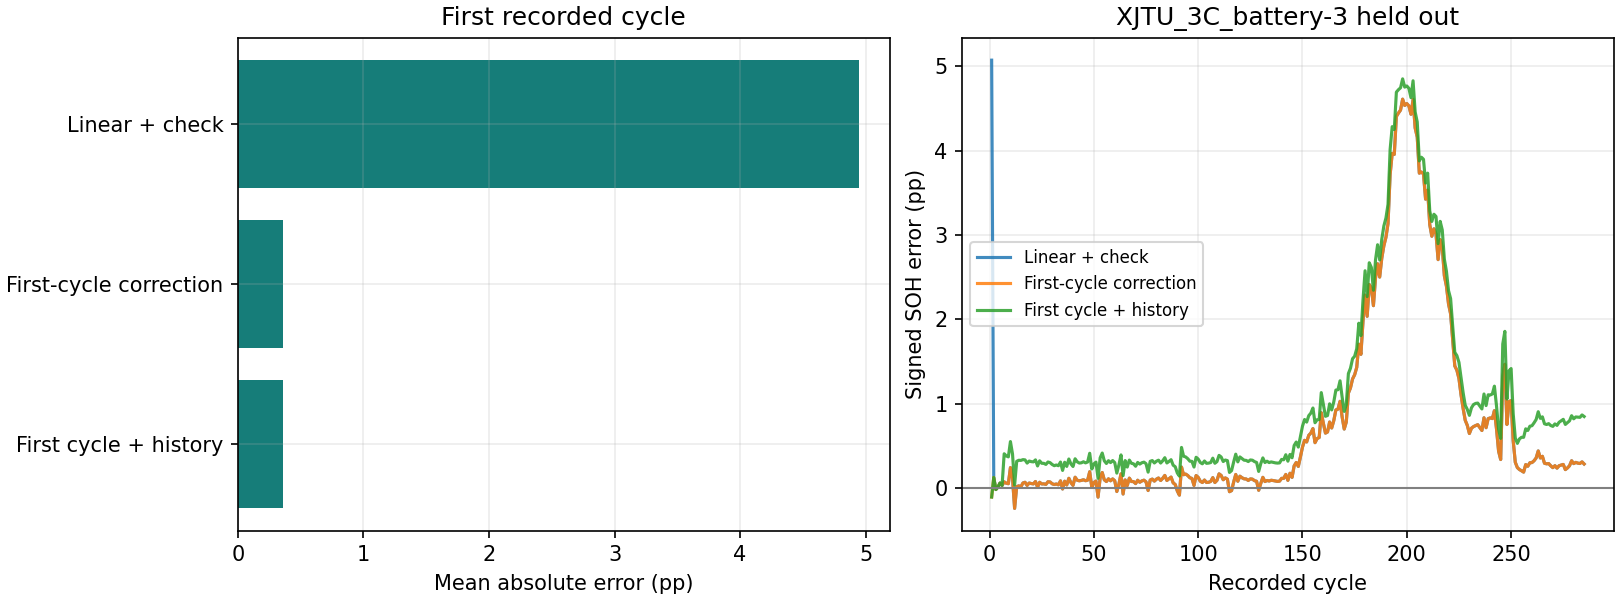

Download lifeguard_soh_error_audit_results.zip from the notebook output.


In [15]:
check_guard_causality()
check_charge_history()
soh_path = locate_soh_export(INPUT_ROOT)
print(f"Reading cycle tables from {soh_path}")
cycles = add_charge_history(load_cycles(soh_path))
splits, split_table = build_splits()
with threadpool_limits(limits=1):
    predictions, adjustments = run_comparison(cycles, splits)
validate_predictions(cycles, splits, predictions)
scored, metrics = score_predictions(predictions)
decision, choice = assess_candidates(metrics)
first, hotspot, by_cell = paired_transfer_diagnostics(scored)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
destination = OUTPUT_ROOT / "lifeguard_soh_error_audit_results.zip"
config = {
    "dataset": "BatteryLife v12", "dataset_doi": "10.5281/zenodo.21149533", "soh_input": soh_path.name,
    "seed": SEED, "nominal_capacity_ah": NOMINAL_AH, "flag_history": HISTORY_SIZE,
    "flag_min_history": MIN_FLAG_HISTORY, "flag_mad_multiplier": MAD_MULTIPLIER, "flag_floors": FLAG_FLOORS,
    "fallback_count": FALLBACK_COUNT, "history_charge_count": HISTORICAL_CHARGES,
    "ridge_alpha": RIDGE_ALPHA, "ridge_fields": RIDGE_FIELDS, "near_eol_soh_pct": NEAR_EOL_SOH,
    "large_error_pp": LARGE_ERROR_PP, "chosen_model": choice,
    "packages": {pkg: version(pkg) for pkg in ("numpy", "pandas", "scikit-learn", "matplotlib")},
}
with TemporaryDirectory(prefix="lifeguard_soh_audit_", dir=OUTPUT_ROOT) as directory:
    output = Path(directory) / "results"
    output.mkdir()
    anomaly = scored.loc[scored.cell_id.eq(OUTLIER_CELL) & scored.cycle.eq(OUTLIER_CYCLE)]
    for filename, table in (
        ("metrics.csv", metrics), ("predictions.csv", scored), ("cell_splits.csv", split_table),
        ("model_selection.csv", decision), ("fold_adjustments.csv", adjustments),
        ("first_cycle_predictions.csv", first), ("hotspot_predictions.csv", hotspot),
        ("transfer_cell_metrics.csv", by_cell), ("cycle_390_comparison.csv", anomaly),
    ):
        table.to_csv(output / filename, index=False)
    (output / "run_config.json").write_text(json.dumps(config, indent=2) + "\n", encoding="utf-8")
    write_summary(output / "summary.md", metrics, first, hotspot, decision, choice, cycles)
    plot_diagnostics(first, hotspot, output / "soh_error_diagnostics.png")
    package_results(output, destination)
    display(Markdown((output / "summary.md").read_text(encoding="utf-8")))
    display(Image(filename=str(output / "soh_error_diagnostics.png")))

print(f"Download {destination.name} from the notebook output.")